# Numerical analysis with NumPy — trainer solution
### Session 11 · NumPy & Numerical Computing

This is the completed reference for the 14-day, three-hub **synthetic** dispatch analysis. Keep the learner starter separate until learners have attempted its tasks. The task prompts and cell order match the learner notebook; each worked code cell follows its corresponding prompt.

**Run:** Use Python 3 with NumPy and Matplotlib. Run the numerical cells from the top in a fresh kernel. The separate image demonstration at the end also needs Pillow and the supplied `S11_Beach_Image.jpg` in the **same working directory as this notebook**. In Jupyter, open this notebook from that folder. If a package is missing, install it into the Python environment used by your notebook kernel and restart the kernel. No sign-in, API, earlier project or external numerical data is needed. The numerical work runs without the photograph or Pillow.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

NumPy: 1.26.4
Matplotlib: 3.8.4


## 1. From two orders to aligned numerical values

In an earlier retailer example, two orders each had a unit price of 250.0, a 10% discount, and 5% tax **after** the discount. Their quantities were 4 and 5. The numeric inputs can be aligned by position: position 0 is the first order and position 1 is the second. Business records remain useful for describing orders; a numeric array is useful when the same arithmetic applies to a collection of numbers.

**Predict:** What does Python list `+` do? What does NumPy array `+` do? Then run this short bridge.

In [2]:
print("List +:", [1, 2] + [3, 4])
print("Array +:", np.array([1, 2]) + np.array([3, 4]))

quantities = np.array([4, 5])
unit_prices = np.array([250.0, 250.0])
discount_rate = 0.10
tax_rate = 0.05
order_totals = quantities * unit_prices * (1 - discount_rate) * (1 + tax_rate)
print("Discount, then tax:", order_totals)

List +: [1, 2, 3, 4]
Array +: [4 6]
Discount, then tax: [ 945.   1181.25]


The two totals are **945.00** and **1181.25**. NumPy performs the arithmetic on matching positions without writing a separate expression for each order. That only makes sense because the positions have the same order in both arrays.

## 2. Arrays carry structure as well as values

An array's **shape** gives its length along each axis; `ndim` counts axes; `size` counts values; `dtype` describes the element type. A 2-D array is often called a **matrix** and a 1-D array a **vector**. Those names do not determine what a row or column means: we must supply the labels.

**Predict:** For the tiny array below, which value is at row index 1, column index 2? How many values and axes does it have? Index 1 is the *second* row.

In [3]:
tiny = np.array([[8, 9, 10], [11, 12, 13]])
print(tiny)
print("shape:", tiny.shape, "ndim:", tiny.ndim, "size:", tiny.size, "dtype:", tiny.dtype)
print("row 1, column 2:", tiny[1, 2])
print("counting sequence:", np.arange(1, 5))
print("zeros:", np.zeros((2, 3)))
print("ones:", np.ones(3))
print("evenly spaced values:", np.linspace(0, 1, 3))
print("mixed numeric dtype:", np.array([1, 2.5]).dtype)

[[ 8  9 10]
 [11 12 13]]
shape: (2, 3) ndim: 2 size: 6 dtype: int32
row 1, column 2: 13
counting sequence: [1 2 3 4]
zeros: [[0. 0. 0.]
 [0. 0. 0.]]
ones: [1. 1. 1.]
evenly spaced values: [0.  0.5 1. ]
mixed numeric dtype: float64


NumPy normally uses one dtype for all values in an array. Mixing whole and decimal numbers can lead to a floating dtype. The exact default integer width can differ by environment; inspect `dtype` rather than assuming one.

### Select, slice, and filter on a small grid

`grid[row, column]` selects one value. A colon means “take all positions” on that axis. A comparison produces a **Boolean mask** with the same shape as the grid; using the full mask to select values produces a **1-D result**. Predict the shapes before running.

In [4]:
grid = np.array([[2, 5, 8], [3, 6, 9]])
mask = grid > 5
print("one row:", grid[1, :], "shape:", grid[1, :].shape)
print("one column:", grid[:, 2], "shape:", grid[:, 2].shape)
print("mask:", mask, "shape:", mask.shape)
print("selected values:", grid[mask], "shape:", grid[mask].shape)

one row: [3 6 9] shape: (3,)
one column: [8 9] shape: (2,)
mask: [[False False  True]
 [False  True  True]] shape: (2, 3)
selected values: [8 6 9] shape: (3,)


Basic slicing commonly returns a **view**: changing the slice can change its source. Boolean selection returns a copy. The example uses a separate array so our dispatch input stays untouched. Use `.copy()` when you need an independent result from a basic slice.

In [5]:
sample = np.array([2, 5, 8])
slice_view = sample[:2]
filtered_copy = sample[sample > 4]
slice_view[0] = 20
filtered_copy[0] = 50
print("source after edits:", sample)
print("filtered copy after edit:", filtered_copy)

source after edits: [20  5  8]
filtered copy after edit: [50  8]


### One operation, many values

Scalar arithmetic applies to each element. Equally shaped arrays combine position by position. **Broadcasting** also lets compatible smaller shapes align from the *right*: `(14, 3)` and `(3,)` fit because their final axis lengths are both 3. A length-14 vector does **not** directly align with the final axis of length 3. Compatible shapes alone are not enough: each position must also refer to the correct hub.

In [6]:
example = np.array([[10, 20, 30], [11, 21, 31]])
print("scalar arithmetic:", example + 2)
print("same-shape arithmetic:", example + np.ones((2, 3)))
print("one number per column:", example / np.array([10, 20, 30]))

scalar arithmetic: [[12 22 32]
 [13 23 33]]
same-shape arithmetic: [[11. 21. 31.]
 [12. 22. 32.]]
one number per column: [[1.         1.         1.        ]
 [1.1        1.05       1.03333333]]


## 3. The 14-day dispatch review

The next cell is **supplied input**. `raw_dispatch_units` is flat and in **day-major order**: East, Central, West for Day 1, then East, Central, West for Day 2, and so on. `daily_capacity` contains **nominal planned daily benchmarks**, one for each hub in the same column order. It is a comparison reference, not a physical maximum.

The 42 readings are new synthetic fulfilment data; they do not come from the earlier sales orders. Run this cell as given. No transcription or file loading is needed.

In [7]:
hub_names = ["East Hub", "Central Hub", "West Hub"]
days = np.arange(1, 15)  # human Day 1 through Day 14
daily_capacity = np.array([110, 95, 120])  # East, Central, West; units per hub per day

raw_dispatch_units = [
    102, 89, 117,   # Day 1
    110, 94, 121,   # Day 2
    115, 93, 118,   # Day 3
    107, 100, 119,  # Day 4
    119, 98, 125,   # Day 5
    92, 84, 109,    # Day 6
    87, 80, 104,    # Day 7
    105, 90, 116,   # Day 8
    112, 97, 119,   # Day 9
    108, 95, 120,   # Day 10
    116, 99, 126,   # Day 11
    121, 103, 131,  # Day 12
    96, 85, 112,    # Day 13
    91, 83, 106,    # Day 14
]

print("readings:", len(raw_dispatch_units))
print("days:", days.shape, "capacity:", daily_capacity.shape)
print("hub order:", hub_names)

readings: 42
days: (14,) capacity: (3,)
hub order: ['East Hub', 'Central Hub', 'West Hub']


### TODO 1 — Make the day-by-hub matrix

**Why:** A flat list has values but no explicit day/hub axes. Convert it to a NumPy array, then reshape to **14 rows × 3 columns**. Axis 0 must mean **day** and axis 1 **hub**. The first row should still be Day 1 in East, Central, West order.

**Predict:** `dispatch.shape`, `dispatch.ndim`, `dispatch.size`, and the shape of `dispatch[0, :]`. The completed expression follows. The supplied checks still catch a wrong shape or wrong first row.

In [8]:
# Task 1 worked answer: convert the flat sequence, then reshape in its existing day-major order.
dispatch = np.array(raw_dispatch_units).reshape(14, 3)

assert isinstance(dispatch, np.ndarray) and dispatch.shape == (14, 3), "Check the 14 day rows and 3 hub columns."
assert np.array_equal(dispatch[0, :], [102, 89, 117]), "Check Day 1 and the East/Central/West column order."
print("shape:", dispatch.shape, "ndim:", dispatch.ndim, "dtype:", dispatch.dtype, "size:", dispatch.size)
print("Day 1:", dispatch[0, :])

shape: (14, 3) ndim: 2 dtype: int32 size: 42
Day 1: [102  89 117]


**Read the result:** `(14, 3)` means 14 day rows and three hub columns, not 14 hubs. The flat input was already grouped East/Central/West for each day; reshaping preserves that order. A different flat order could still produce `(14, 3)` while assigning readings to the wrong hub or day.

### TODO 2 — Select days, a hub, and a condition

**Why:** A row answers “what happened on one day?”, while a column answers “what happened at one hub across days?”. Use zero-based indices: Day 2 is row index **1**; West is column index **2**.

Select Day 2, all West readings, and Days 1–7. Then select readings **strictly greater than the fixed value 120 units**. This strict fixed-value mask is only a filtering exercise; it is *different* from the per-hub capacity comparison in TODO 3. Use the full mask to collect matching values.

**Predict:** shapes of the day row, hub column, week block, full mask, and filtered result. Why does the filtered result no longer show day-by-hub positions?

In [9]:
# Task 2 worked answer: select and filter the dispatch array.
day2 = dispatch[1, :]
west_series = dispatch[:, 2]
week1_slice = dispatch[:7, :]
large_reading_mask = dispatch > 120       # compare all dispatch values with 120
large_readings = dispatch[large_reading_mask]          # use the full mask to select values

assert np.shape(day2) == (3,), "Day 2 should have one value per hub."
assert np.shape(west_series) == (14,), "West should have one value per day."
assert np.shape(week1_slice) == (7, 3), "Week 1 should contain seven day rows and three hub columns."
assert np.shape(large_reading_mask) == (14, 3), "Compare every cell to form a full-size mask."
assert np.ndim(large_readings) == 1, "A full-array Boolean selection should be 1-D."
print("Day 2:", day2, "West series:", west_series)
print("Week 1 shape:", week1_slice.shape)
print("mask shape:", large_reading_mask.shape, "selected shape:", np.shape(large_readings))
print("selected values:", large_readings)

Day 2: [110  94 121] West series: [117 121 118 119 125 109 104 116 119 120 126 131 112 106]
Week 1 shape: (7, 3)
mask shape: (14, 3) selected shape: (5,)
selected values: [121 125 126 121 131]


**Read the result:** Day 2 is `[110, 94, 121]` in hub order. The Boolean mask keeps the `(14, 3)` grid; selecting with that full mask makes a 1-D list of qualifying values. The `> 120` filter is an absolute reading threshold and says nothing about the three different hub benchmarks.

### TODO 3 — Broadcast a benchmark across all days

**Why:** Every row has the same three hub columns, so one three-value benchmark vector can be used against all 14 rows. Calculate the **dimensionless ratio** `actual / nominal benchmark`. A ratio of `1.0` means exactly at benchmark; only a ratio **greater than** `1.0` means strictly above it.

Create `exceeded` using a strict `>` comparison. Also identify exact equalities in `at_capacity`. Check Day 2: East equals its benchmark; ask whether West is above its own benchmark. A day above a *nominal* benchmark does not prove failure or an impossible shipment.

**Prediction:** Why will a `(14,)` vector not directly broadcast across a `(14, 3)` matrix? Compare shapes from the **trailing axis**.

In [10]:
# Task 3 worked answer: use the hub-aligned capacity vector; do not loop over days.
utilisation = dispatch / daily_capacity
exceeded = dispatch > daily_capacity
at_capacity = dispatch == daily_capacity

assert np.shape(utilisation) == (14, 3), "The ratio needs one value per hub-day cell."
assert np.shape(exceeded) == (14, 3) and np.asarray(exceeded).dtype == bool, "exceeded needs a full Boolean mask."
assert np.shape(at_capacity) == (14, 3) and np.asarray(at_capacity).dtype == bool, "at_capacity needs a full Boolean mask."
assert np.isclose(utilisation[1, 0], 1.0), "Day 2 East should equal its nominal benchmark."
assert not exceeded[1, 0] and at_capacity[1, 0], "Equality is not a strict exceedance."
print("ratio shape:", np.shape(utilisation), "ratio dtype:", np.asarray(utilisation).dtype)
print("Day 2 ratios (East, Central, West):", utilisation[1, :])
print("Day 2 strictly above benchmark?:", exceeded[1, :])

ratio shape: (14, 3) ratio dtype: float64
Day 2 ratios (East, Central, West): [1.         0.98947368 1.00833333]
Day 2 strictly above benchmark?: [False False  True]


In [11]:
# Equality and exceedance refer to each hub's own nominal benchmark.
equal_positions = np.argwhere(at_capacity)
print("exactly at benchmark (human day, hub):")
for day_index, hub_index in equal_positions:
    print(int(days[day_index]), hub_names[hub_index])
print("strictly above benchmark on Day 2:", [hub_names[i] for i in np.flatnonzero(exceeded[1, :])])

exactly at benchmark (human day, hub):
2 East Hub
10 Central Hub
10 West Hub
strictly above benchmark on Day 2: ['West Hub']


**Read the result:** `(14, 3) / (3,)` aligns the three benchmark values with the three hub columns on every day. `(14,)` would try to match the last axis of length 3, so it does not broadcast directly. Day 2 East is exactly at its benchmark (`1.0`), while West alone is strictly above; equality belongs in `at_capacity`, not `exceeded`. A nominal benchmark is a planning reference, not a physical maximum.

### TODO 4 — Reduce an axis, keep its meaning

**Why:** `axis=0` collapses the **day rows**, leaving one 14-day total for each hub. `axis=1` collapses the **hub columns**, leaving one network total for each day. Give every result a unit and label.

Compute hub totals, day totals, a mean network day, the smallest and largest network day totals, and the zero-based index of the busiest day. Convert that index to a human day using `days`. Count above-benchmark cells overall and by hub; count distinct days with at least one above-benchmark hub. Boolean `True` values count as 1 when summed. A standard deviation gives a brief measure of how much daily totals vary around their mean; it does not explain *why* they vary.

In [12]:
# Task 4 worked answer: reduce over the intended axes and label each result.
hub_totals = dispatch.sum(axis=0)
day_totals = dispatch.sum(axis=1)
mean_network_day = day_totals.mean()
min_daily_total = day_totals.min()
max_daily_total = day_totals.max()
peak_index = day_totals.argmax()
peak_day = days[peak_index]
above_by_hub = exceeded.sum(axis=0)
above_cells = exceeded.sum()
above_days = np.any(exceeded, axis=1).sum()
daily_total_std = day_totals.std()

assert np.shape(hub_totals) == (3,), "Hub totals should leave the hub axis."
assert np.shape(day_totals) == (14,), "Daily totals should leave the day axis."
assert np.shape(above_by_hub) == (3,), "Counts by hub should leave the hub axis."
assert 0 <= peak_index < 14 and peak_day == days[peak_index], "Translate the zero-based peak index using days."
print("14-day hub totals (units):", dict(zip(hub_names, hub_totals)))
print("daily network totals (units):", day_totals)
print("mean network day (units):", mean_network_day)
print("daily minimum / maximum (units):", min_daily_total, max_daily_total)
print("busiest human day:", peak_day, "at zero-based index:", peak_index)
print("strictly above benchmark by hub:", dict(zip(hub_names, above_by_hub)))
print("above-benchmark hub-day cells / distinct days:", above_cells, above_days)
print("standard deviation of daily network totals (units):", daily_total_std)

14-day hub totals (units): {'East Hub': 1481, 'Central Hub': 1290, 'West Hub': 1643}
daily network totals (units): [308 325 326 326 342 285 271 311 328 323 341 355 293 280]
mean network day (units): 315.2857142857143
daily minimum / maximum (units): 271 355
busiest human day: 12 at zero-based index: 11
strictly above benchmark by hub: {'East Hub': 5, 'Central Hub': 5, 'West Hub': 4}
above-benchmark hub-day cells / distinct days: 14 7
standard deviation of daily network totals (units): 24.185085638610808


In [13]:
grand_total = dispatch.sum()
above_day_labels = days[np.any(exceeded, axis=1)]
print("all-hub total (units):", grand_total)
print("human days with at least one above-benchmark hub:", above_day_labels)
print("exact equality cells:", at_capacity.sum())

all-hub total (units): 4414
human days with at least one above-benchmark hub: [ 2  3  4  5  9 11 12]
exact equality cells: 3


**Read the result:** `axis=0` sums *over days* and leaves three hub totals; `axis=1` sums *over hubs* and leaves 14 daily network totals. The largest daily total is 355 units on human Day 12, although `argmax` returns zero-based index 11. There are 14 above-benchmark **hub-day cells** on seven distinct **days**; these count different things. The mean is an average daily network total. The standard deviation describes variation of these 14 totals around that mean, without explaining its cause.

### TODO 5 — Split the timeline and rebuild it

**Why:** The first seven rows are Days 1–7, and the next seven are Days 8–14. Split **along the day axis**, compare the weekly totals, then stack Week 1 above Week 2. Matching shapes are not proof of matching chronology: check the actual values with `np.array_equal`.

**Hint:** `np.split()` can divide an array into two equal blocks along `axis=0` (rows). `np.vstack()` places blocks one above the other in the order you give them.

In [14]:
# Task 5 worked answer: split into two weeks along the day axis.
weeks = np.split(dispatch, 2, axis=0)
assert len(weeks) == 2 and all(np.shape(week) == (7, 3) for week in weeks), "Each week needs shape (7, 3)."
week1, week2 = weeks

week1_total = week1.sum()
week2_total = week2.sum()
rebuilt = np.vstack((week1, week2))                 # stack Week 1 above Week 2
same_as_original = np.array_equal(rebuilt, dispatch)        # compare every value and its position
assert np.shape(rebuilt) == (14, 3), "Rebuilt data should have the original shape."
assert same_as_original, "Recheck the order of the weekly blocks with np.array_equal."
print("Week 1 / Week 2 (units):", week1_total, week2_total)
print("Week 2 minus Week 1 (units):", week2_total - week1_total)
print("original recovered?:", same_as_original)

Week 1 / Week 2 (units): 2183 2231
Week 2 minus Week 1 (units): 48
original recovered?: True


**Read the result:** The two `(7, 3)` blocks remain in chronological order. Week 2 has 48 more dispatched units than Week 1. `np.array_equal` verifies every value's position after re-stacking; matching shape alone would not.

## 4. Turn the results into three different views

Each chart answers a different question. The figure and label code is supplied so you can focus on choosing the **right array for each axis**. Each chart cell below shows the completed data expressions. Keep the labels, units and titles; run the charts only after TODOs 1–5.

### TODO 6a — Line: daily network dispatch

X should be human Days 1–14. Y should contain **one total across all hubs for each day**, not 42 individual hub readings. A line helps reveal change over time, without explaining its cause.

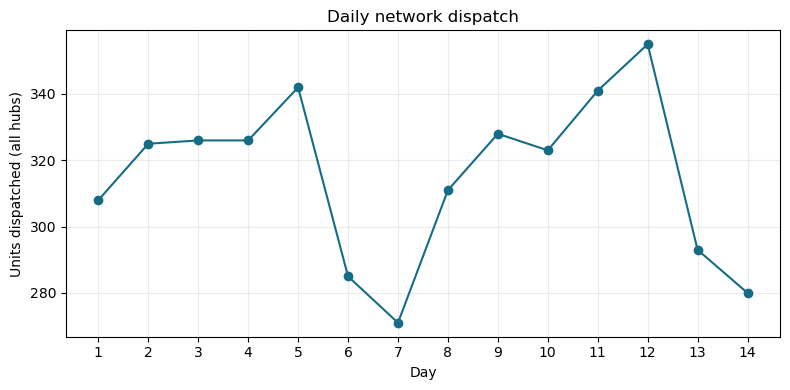

In [15]:
# Task 6a worked answer: plot human day labels against daily network totals.
line_x = days
line_y = day_totals
assert np.shape(line_x) == (14,) and np.shape(line_y) == (14,), "The line needs 14 paired day/total values."
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(line_x, line_y, marker="o", color="#166c84")
ax.set(title="Daily network dispatch", xlabel="Day", ylabel="Units dispatched (all hubs)")
ax.set_xticks(days)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### TODO 6b — Bar: cumulative units by hub

X should preserve **East, Central, West** order. Y should be the three **14-day hub totals**, not the three nominal daily benchmarks. A bar chart compares category totals.

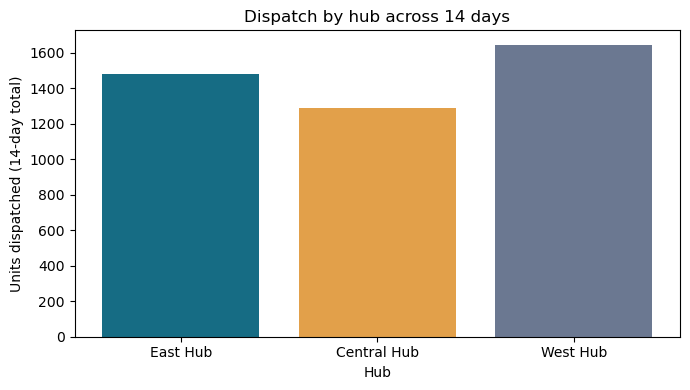

In [16]:
# Task 6b worked answer: plot hub names against their 14-day totals.
bar_x = hub_names
bar_y = hub_totals
assert len(bar_x) == 3 and np.shape(bar_y) == (3,), "The bar chart needs three matched hubs and totals."
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(bar_x, bar_y, color=["#166c84", "#e2a04a", "#6b7891"])
ax.set(title="Dispatch by hub across 14 days", xlabel="Hub", ylabel="Units dispatched (14-day total)")
fig.tight_layout()
plt.show()

### TODO 6c — Scatter: paired East and West days

Each point must pair **East and West from the same day**. X is East's 14 daily readings; Y is West's 14 daily readings. A visible pattern does not by itself establish a cause or say whether either hub met its benchmark.

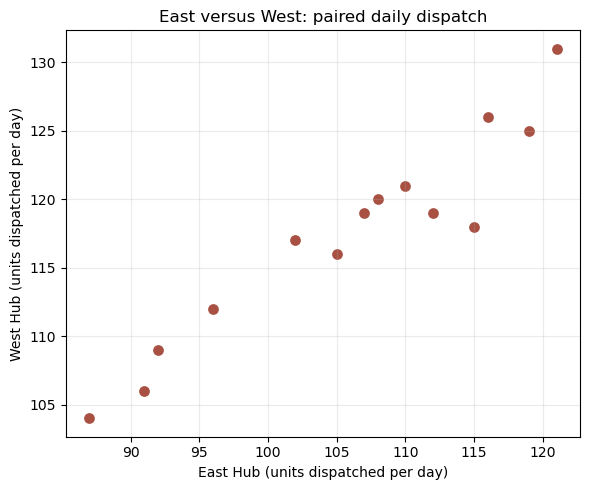

In [17]:
# Task 6c worked answer: pair East and West values from matching days.
scatter_x = dispatch[:, 0]
scatter_y = dispatch[:, 2]
assert np.shape(scatter_x) == (14,) and np.shape(scatter_y) == (14,), "The scatter needs 14 paired hub-day readings."
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(scatter_x, scatter_y, color="#a85142", s=45)
ax.set(title="East versus West: paired daily dispatch", xlabel="East Hub (units dispatched per day)",
       ylabel="West Hub (units dispatched per day)")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**Chart check:** The line uses 14 daily network totals; the bar uses three 14-day hub totals; the scatter uses 14 East/West pairs from the same days. These choices answer time, category, and paired-value questions respectively. A scatter pattern describes association in these readings; it does not identify a cause.

## 5. Interpret your evidence — worked example

1. **Timeline:** The busiest network day is **Day 12**, with **355 units** dispatched across the three hubs. The line chart shows day-to-day variation, including the lower Day 7 total of **271 units**.
2. **Hubs and weeks:** Across 14 days, **West Hub** has the largest total (**1,643 units**); East has **1,481** and Central **1,290**. Week 2 totals **2,231 units**, **48** more than Week 1's **2,183**.
3. **Benchmarks:** There are **14 strictly above-benchmark hub-day cells** across **seven distinct days**. Day 2 West is above its own nominal benchmark, while Day 2 East is exactly at its benchmark and is not an exceedance.
4. **Limitation:** These synthetic dispatch counts and nominal benchmarks do not show staffing, demand, delivery speed, service quality or the cause of any busy day. The East/West scatter can show how paired values vary together, but it cannot establish causation.

### Optional comparison — “at or above” is a different question

The learner starter asks what changes if `>=` replaces `>`. Run the comparison below. It includes exactly-at-benchmark cells, so its count must **not** be labelled “strictly above benchmark”.


In [18]:
at_or_above = dispatch >= daily_capacity
print("strictly above benchmark:", exceeded.sum())
print("exactly at benchmark:", at_capacity.sum())
print("at or above benchmark:", at_or_above.sum())
assert np.array_equal(at_or_above, exceeded | at_capacity)


strictly above benchmark: 14
exactly at benchmark: 3
at or above benchmark: 17


## Trainer demonstration — NumPy arrays as images

This short demonstration uses the supplied beach photograph to transfer the same **shape, slicing and vectorisation** ideas to pixels. It is separate from the hub practical and does not replace the line, bar or scatter charts.

Place **`S11_Beach_Image.jpg` beside this notebook** and run Jupyter with that folder as the working directory. The image cells require Pillow. If the file is missing, the first image cell raises a clear `FileNotFoundError`; the completed numerical solution above remains usable. The photo is a supplied teaching asset; confirm applicable reuse permission before distributing it beyond the intended class materials.


### 1. Load and inspect the actual photograph

An RGB image uses three numerical values per pixel. Its axes here are **row, column, colour channel**. Three axes do not imply a three-dimensional spatial scene. Predict the array shape from a photo 900 pixels high and 720 pixels wide, then inspect one genuine pixel.


source: JPEG RGB (720, 900) (width, height)
array shape / ndim / dtype: (900, 720, 3) 3 uint8
RGB pixel at row 300, column 360: [216 194 180]


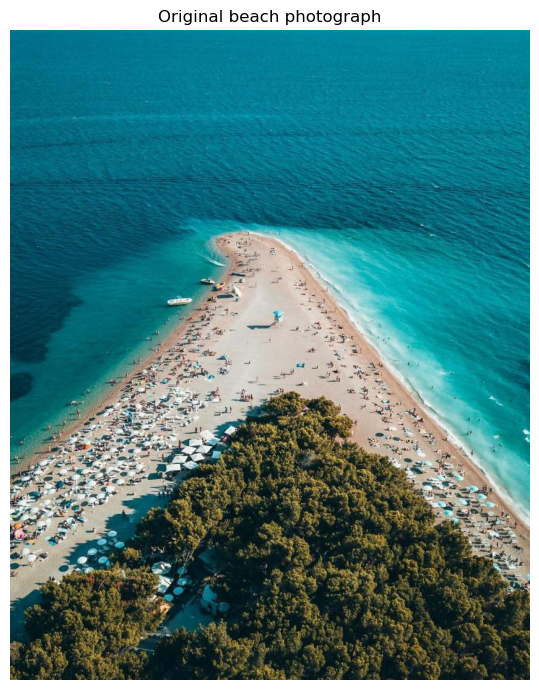

In [19]:
from pathlib import Path
from PIL import Image

image_path = Path("S11_Beach_Image.jpg")
if not image_path.is_file():
    raise FileNotFoundError(
        "Place S11_Beach_Image.jpg beside the notebook and run from that folder before the image demonstration."
    )

with Image.open(image_path) as photo:
    source_format, source_mode, source_size = photo.format, photo.mode, photo.size
    image = np.asarray(photo.convert("RGB"))

assert source_format == "JPEG" and source_mode == "RGB" and source_size == (720, 900)
assert image.shape == (900, 720, 3) and image.ndim == 3 and image.dtype == np.uint8
pixel = image[300, 360, :]
print("source:", source_format, source_mode, source_size, "(width, height)")
print("array shape / ndim / dtype:", image.shape, image.ndim, image.dtype)
print("RGB pixel at row 300, column 360:", pixel)

fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(image)
ax.set_title("Original beach photograph")
ax.axis("off")
fig.tight_layout()
plt.show()

### 2. Crop with ordinary NumPy slices

Take rows `250:550`, columns `120:600`, and all three channels. The endpoints are excluded, so the crop should have **300 rows × 480 columns × 3 channels**. This is the same slicing idea used for a week of dispatch readings.


crop shape: (300, 480, 3)


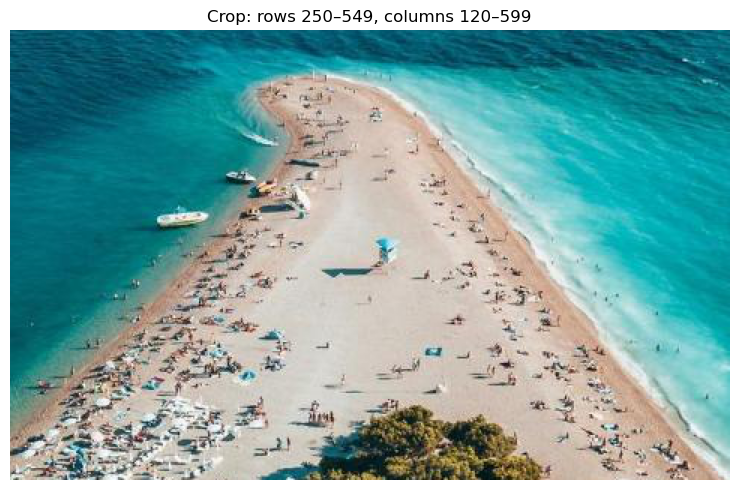

In [20]:
crop = image[250:550, 120:600, :]
assert crop.shape == (300, 480, 3)
print("crop shape:", crop.shape)

fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(crop)
ax.set_title("Crop: rows 250–549, columns 120–599")
ax.axis("off")
fig.tight_layout()
plt.show()

### 3. Brighten the full image safely

Unsigned 8-bit pixels hold values from 0 to 255. Convert to floating point **before** multiplying by `1.20`, clip to the valid range, then convert back to `uint8`. The original array is left unchanged. `plt.imshow` displays the resulting pixels; it is not another required numerical chart.


original / brightened pixel at row 300, column 360: [216 194 180] [255 232 216]
brightened value range: 0 255


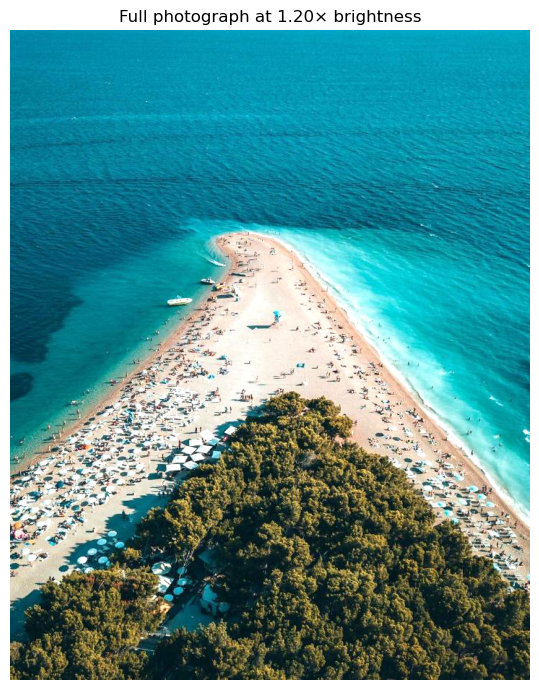

In [21]:
original_pixels = image.copy()
brightness_factor = 1.20
brightened = np.clip(image.astype(np.float32) * brightness_factor, 0, 255).astype(np.uint8)
assert brightened.shape == image.shape and brightened.dtype == np.uint8
assert np.array_equal(image, original_pixels)
assert np.any(brightened != image)
print("original / brightened pixel at row 300, column 360:", image[300, 360, :], brightened[300, 360, :])
print("brightened value range:", brightened.min(), brightened.max())

fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(brightened)
ax.set_title("Full photograph at 1.20× brightness")
ax.axis("off")
fig.tight_layout()
plt.show()

**Transfer:** The dispatch case and photograph are different kinds of data, yet NumPy applies the same ideas: axes give positions meaning, slices select a region, and one arithmetic expression acts across many numbers. This previews later image-array work without attempting image recognition or model training.
